# Comparative Analysis: Cascade vs LDPC vs Winnow vs Polar Codes
## BB84 QKD Reconciliation Protocols

This notebook provides a detailed comparison between four major reconciliation protocols used in Quantum Key Distribution:
1.  **Cascade**: An interactive, multi-pass protocol based on binary search.
2.  **5G NR-LDPC**: A rate-adaptive syndrome decoder using the 3GPP QC-LDPC structure, belief propagation, OSD-0, and hash verification.
3.  **Winnow**: An interactive protocol using Hamming codes to correct errors with fewer round trips than Cascade.
4.  **Polar Codes**: An advanced interactive scheme using Polar decoding capable of approaching channel capacity.

We evaluate them based on:
*   **Leakage**: How much key material is sacrificed.
*   **Efficiency**: Proximity to the Shannon Limit.
*   **Latency**: Number of network round-trips required.
*   **Speed**: Computational execution time.

In [1]:
import asyncio
import random
import sys
import os
import math
import time
import matplotlib.pyplot as plt
import numpy as np

# Ensure we can import from the ServerClientBB84 directory
current_dir = os.getcwd()
target_dir = os.path.join(current_dir, 'ServerClientBB84')
if target_dir not in sys.path:
    sys.path.append(target_dir)

try:
    from bb84_server_client import AliceServer, BobClient, QuantumChannel, Detector, Eve, APIClient
except ImportError:
    sys.path.append(os.getcwd())
    from bb84_server_client import AliceServer, BobClient, QuantumChannel, Detector, Eve, APIClient

# Enable inline plotting
%matplotlib inline

print("Libraries imported successfully.")
print("Note: NR-LDPC uses the standalone QC-LDPC fallback when TensorFlow/Sionna is unavailable; Sionna is optional.")

[LDPC] NVIDIA Sionna (3GPP TS 38.212 5G NR LDPC) loaded.
Libraries imported successfully.
Note: NR-LDPC uses the standalone QC-LDPC fallback when TensorFlow/Sionna is unavailable; Sionna is optional.


In [2]:
async def run_comparison_simulation(protocol="cascade",
                                    num_qubits=5000,
                                    optical_error_rate=0.01,
                                    verbose=False,
                                    seed_base=44444):
    """Run one server/client BB84 reconciliation simulation."""
    channel = QuantumChannel(
        "Fiber", length_km=50, attenuation_db=0.2,
        optical_error_rate=optical_error_rate, next_actor=None, seed=seed_base,
    )
    alice = AliceServer(
        "Alice", channel, num_qubits=num_qubits, verbose=verbose,
        seed=seed_base + 1,
    )
    api = APIClient(alice)
    protocol_params = (
        {"max_k": 4224, "max_sweep_iter": 12, "hash_bits": 12}
        if protocol in {"nr_ldpc_std", "nr_ldpc_standard", "ldpc_5g_std"}
        else None
    )
    bob = BobClient(
        "Bob", api, protocol=protocol, protocol_params=protocol_params,
        seed=seed_base + 2, verbose=verbose,
    )
    detector = Detector(
        "Detector", efficiency=0.8, dark_count_prob=0.01,
        parent_bob=bob, seed=seed_base + 3,
    )
    eve = Eve("Eve", next_actor=detector, intercept_rate=0.2, seed=seed_base + 5)
    channel.next_actor = eve

    actors = [alice, channel, eve, detector, bob]
    tasks = [asyncio.create_task(actor.start()) for actor in actors]
    try:
        start_time = time.perf_counter()
        await alice.run_quantum_transmission()
        await asyncio.sleep(0.5 + num_qubits * 0.0001)
        results = await bob.run_classical_post_processing(num_qubits)
        results["exec_time"] = time.perf_counter() - start_time
    except Exception as exc:
        if verbose:
            print(f"Error in {protocol} simulation: {exc}")
        results = {"sifted_length": 0}
    finally:
        for actor in actors:
            await actor.send(actor, ("STOP",))
        await asyncio.gather(*tasks, return_exceptions=True)
    return results

async def run_multiple_simulations(protocol, num_qubits, optical_error_rate,
                                   runs=3, verbose=False):
    """Run independent simulations and average per-run measurements."""
    tasks = [
        run_comparison_simulation(
            protocol, num_qubits, optical_error_rate, verbose,
            seed_base=44444 + i * 10,
        )
        for i in range(runs)
    ]
    all_results = await asyncio.gather(*tasks)
    valid = [
        result for result in all_results
        if result.get("sifted_length", 0) > 0 and result.get("qber", 0) > 0
    ]
    if not valid:
        return None

    return {
        "qber": float(np.mean([r["qber"] for r in valid])),
        "revealed": float(np.mean([r["revealed"] for r in valid])),
        "final_length": float(np.mean([r["final_length"] for r in valid])),
        "channel_uses": float(np.mean([r["channel_uses"] for r in valid])),
        "exec_time": float(np.mean([r.get("exec_time", 0) for r in valid])),
        "sifted_length": float(np.mean([r["sifted_length"] for r in valid])),
        "eff_per_run": [
            r["revealed"] / (r["final_length"] * binary_entropy(r["qber"]))
            for r in valid if r["qber"] > 0 and r["final_length"] > 0
        ],
        "leakage_per_run": [
            (r["revealed"] / r["final_length"]) * 100.0
            for r in valid if r["final_length"] > 0
        ],
        "skf_per_run": [
            r.get("pa_length", 0) / r["sifted_length"]
            for r in valid if r["sifted_length"] > 0
        ],
    }

def binary_entropy(p):
    if p <= 0 or p >= 1:
        return 0.0
    return -p * math.log2(p) - (1 - p) * math.log2(1 - p)

def calculate_efficiency(n_revealed, k_sifted, qber):
    if k_sifted == 0 or qber <= 0 or qber >= 1:
        return None
    h_eps = binary_entropy(qber)
    return n_revealed / (k_sifted * h_eps) if h_eps else None

print("Simulation driver and per-run metrics defined.")

Simulation driver and per-run metrics defined.


In [3]:
# --- Experiment 1: Impact of QBER ---

error_rates = np.linspace(0.001, 0.12, 25)
MONTE_CARLO_RUNS = 3

results_cascade = {"qber": [], "leakage": [], "efficiency": [], "uses": [], "skf": []}
results_nr = {"qber": [], "leakage": [], "efficiency": [], "uses": [], "skf": []}
results_winnow = {"qber": [], "leakage": [], "efficiency": [], "uses": [], "skf": []}
results_polar = {"qber": [], "leakage": [], "efficiency": [], "uses": [], "skf": []}
protocol_results = {
    "cascade": results_cascade,
    "nr_ldpc_std": results_nr,
    "winnow": results_winnow,
    "polar": results_polar,
}

N_QUBITS = 100000
print(f"Running QBER sweep (N={N_QUBITS}, runs/point={MONTE_CARLO_RUNS})...")

for err in error_rates:
    print(f"Testing optical error: {err:.3f}...", end="\r")
    for protocol, destination in protocol_results.items():
        average = await run_multiple_simulations(
            protocol, N_QUBITS, err, runs=MONTE_CARLO_RUNS,
        )
        if not average or average["sifted_length"] <= 0 or average["qber"] <= 0:
            continue
        efficiencies = average["eff_per_run"]
        if not efficiencies:
            continue
        destination["qber"].append(average["qber"] * 100)
        destination["leakage"].append(float(np.mean(average["leakage_per_run"])))
        destination["efficiency"].append(float(np.mean(efficiencies)))
        destination["uses"].append(average["channel_uses"])
        destination["skf"].append(float(np.mean(average["skf_per_run"])))

print("\nExperiment 1 complete.")

Running QBER sweep (N=100000, runs/point=3)...
Testing optical error: 0.001...
[BOB] Processing 8426 detection events.
[BOB] First 15 Valid Detections: 1(+), 0(x), 1(+), 1(x), 0(x), 0(+), 0(+), 1(+), 1(+), 1(+), 0(+), 0(x), 1(x), 0(+), 0(x) ...
[BOB] Sending 8426 bases to Alice for sifting...
[BOB] Sifting complete. Bases matched on 4172 events.
[BOB] Sifted Key Preview: [0, 0, 0, 1, 0, 1, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0]...
[BOB] Sampling 834 bits for QBER estimation...
[BOB] QBER Analysis: 48 errors in 834 samples. Estimated QBER = 5.76%
[BOB] Discarding revealed bits. Working Key Size: 3338
[BOB] Initializing Cascade Protocol...

[BOB] Starting Privacy Amplification using toeplitz...

      PRIVACY AMPLIFICATION METRICS
 [+] Reconciled Key Length (N):      3338 bits
 [+] QBER (e):                       5.7554%
 [+] Est. Eve's Knowledge Bound (t): 2247 bits
 [+] Security Parameter (S):         10 bits
 [+] Final Secret Key Length (R):    1081 bits
[BOB] Sent PA seed and prot

I0000 00:00:1793174029.393677   63186 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 4549 MB memory:  -> device: 0, name: NVIDIA GeForce RTX 2060 with Max-Q Design, pci bus id: 0000:01:00.0, compute capability: 7.5



[BOB] Starting Privacy Amplification using toeplitz...

      PRIVACY AMPLIFICATION METRICS
 [+] Reconciled Key Length (N):      3338 bits
 [+] QBER (e):                       5.7554%
 [+] Est. Eve's Knowledge Bound (t): 2448 bits
 [+] Security Parameter (S):         10 bits
 [+] Final Secret Key Length (R):    880 bits
[BOB] Sent PA seed and protocol choice to Alice. Generated secret key of length 880.

[BOB] Processing 8328 detection events.
[BOB] First 15 Valid Detections: 1(+), 0(+), 1(x), 1(x), 1(+), 0(+), 1(+), 1(+), 0(+), 1(x), 1(+), 1(+), 0(x), 1(x), 0(x) ...
[BOB] Sending 8328 bases to Alice for sifting...
[BOB] Sifting complete. Bases matched on 4146 events.
[BOB] Sifted Key Preview: [1, 1, 0, 1, 1, 0, 0, 0, 1, 0, 1, 1, 0, 0, 0, 0, 0, 1, 1, 1]...
[BOB] Sampling 829 bits for QBER estimation...
[BOB] QBER Analysis: 45 errors in 829 samples. Estimated QBER = 5.43%
[BOB] Discarding revealed bits. Working Key Size: 3317
[BOB] Initializing Nr_Ldpc_Std Protocol...
[BOB] Selected Pr

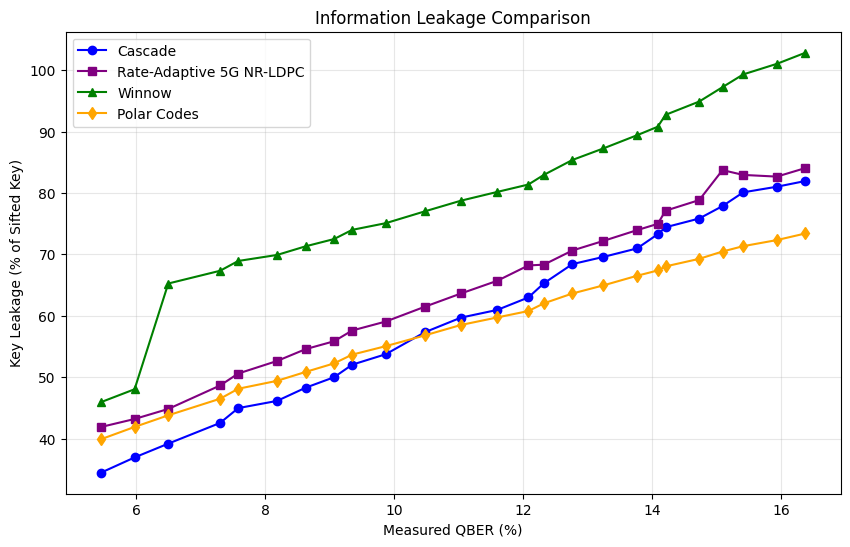

In [4]:
# --- Graph 1: Key Leakage vs QBER ---

plt.figure(figsize=(10, 6))

if len(results_cascade["qber"]) > 0:
    idx_c = np.argsort(results_cascade["qber"])
    plt.plot(np.array(results_cascade["qber"])[idx_c], 
             np.array(results_cascade["leakage"])[idx_c], 
             'o-', color='blue', label='Cascade')

if len(results_nr["qber"]) > 0:
    idx_l = np.argsort(results_nr["qber"])
    plt.plot(np.array(results_nr["qber"])[idx_l], 
             np.array(results_nr["leakage"])[idx_l], 
             's-', color='purple', label='Rate-Adaptive 5G NR-LDPC')

if len(results_winnow["qber"]) > 0:
    idx_w = np.argsort(results_winnow["qber"])
    plt.plot(np.array(results_winnow["qber"])[idx_w], 
             np.array(results_winnow["leakage"])[idx_w], 
             '^-', color='green', label='Winnow')

if len(results_polar["qber"]) > 0:
    idx_p = np.argsort(results_polar["qber"])
    plt.plot(np.array(results_polar["qber"])[idx_p], 
             np.array(results_polar["leakage"])[idx_p], 
             'd-', color='orange', label='Polar Codes')

plt.xlabel('Measured QBER (%)')
plt.ylabel('Key Leakage (% of Sifted Key)')
plt.title('Information Leakage Comparison')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

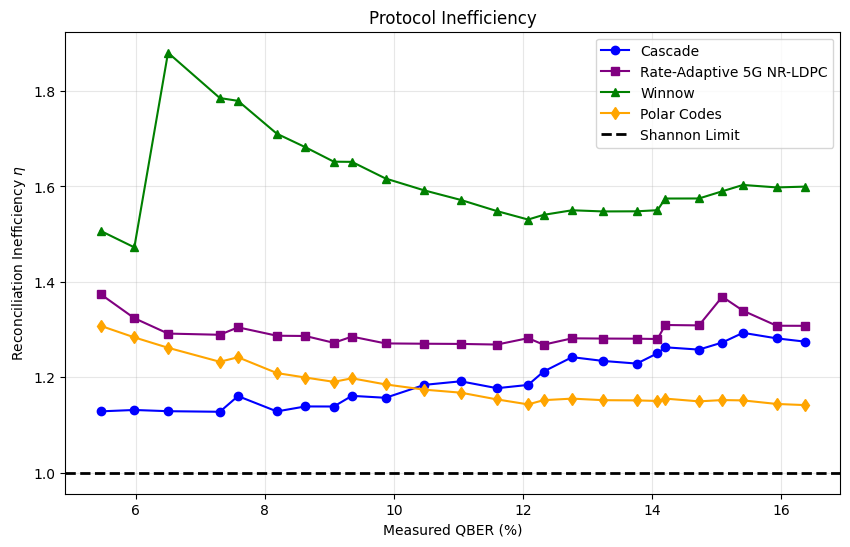

In [5]:
# --- Graph 2: Efficiency vs QBER ---

plt.figure(figsize=(10, 6))

if len(results_cascade["qber"]) > 0:
    idx_c = np.argsort(results_cascade["qber"])
    plt.plot(np.array(results_cascade["qber"])[idx_c], 
             np.array(results_cascade["efficiency"])[idx_c], 
             'o-', color='blue', label='Cascade')

if len(results_nr["qber"]) > 0:
    idx_l = np.argsort(results_nr["qber"])
    plt.plot(np.array(results_nr["qber"])[idx_l], 
             np.array(results_nr["efficiency"])[idx_l], 
             's-', color='purple', label='Rate-Adaptive 5G NR-LDPC')

if len(results_winnow["qber"]) > 0:
    idx_w = np.argsort(results_winnow["qber"])
    plt.plot(np.array(results_winnow["qber"])[idx_w], 
             np.array(results_winnow["efficiency"])[idx_w], 
             '^-', color='green', label='Winnow')

if len(results_polar["qber"]) > 0:
    idx_p = np.argsort(results_polar["qber"])
    plt.plot(np.array(results_polar["qber"])[idx_p], 
             np.array(results_polar["efficiency"])[idx_p], 
             'd-', color='orange', label='Polar Codes')

plt.axhline(y=1.0, color='black', linestyle='--', linewidth=2, label='Shannon Limit')

plt.xlabel('Measured QBER (%)')
plt.ylabel(r'Reconciliation Inefficiency $\eta$')
plt.title('Protocol Inefficiency')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

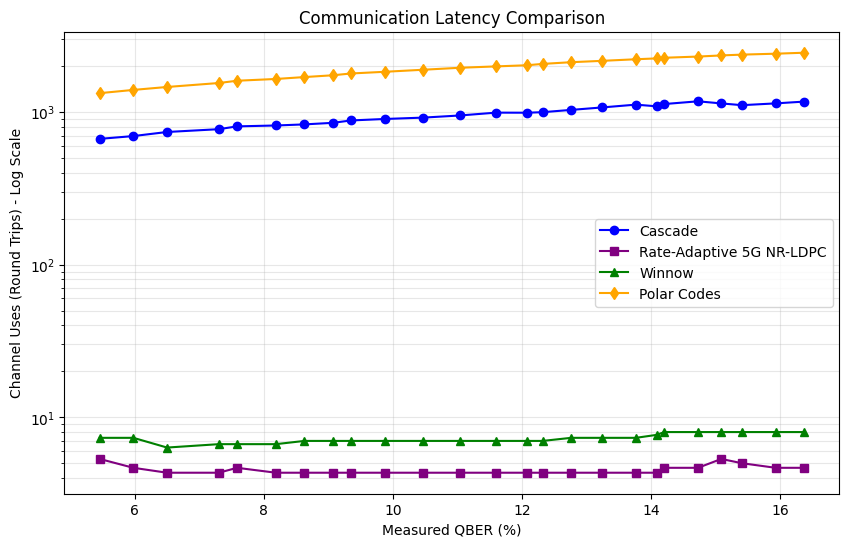

In [6]:
# --- Graph 3: Latency (Round Trips) vs QBER ---

plt.figure(figsize=(10, 6))

if len(results_cascade["qber"]) > 0:
    idx_c = np.argsort(results_cascade["qber"])
    plt.plot(np.array(results_cascade["qber"])[idx_c], 
             np.array(results_cascade["uses"])[idx_c], 
             'o-', color='blue', label='Cascade')

if len(results_nr["qber"]) > 0:
    idx_l = np.argsort(results_nr["qber"])
    plt.plot(np.array(results_nr["qber"])[idx_l], 
             np.array(results_nr["uses"])[idx_l], 
             's-', color='purple', label='Rate-Adaptive 5G NR-LDPC')

if len(results_winnow["qber"]) > 0:
    idx_w = np.argsort(results_winnow["qber"])
    plt.plot(np.array(results_winnow["qber"])[idx_w], 
             np.array(results_winnow["uses"])[idx_w], 
             '^-', color='green', label='Winnow')

if len(results_polar["qber"]) > 0:
    idx_p = np.argsort(results_polar["qber"])
    plt.plot(np.array(results_polar["qber"])[idx_p], 
             np.array(results_polar["uses"])[idx_p], 
             'd-', color='orange', label='Polar Codes')

plt.yscale('log')
plt.xlabel('Measured QBER (%)')
plt.ylabel('Channel Uses (Round Trips) - Log Scale')
plt.title('Communication Latency Comparison')
plt.legend()
plt.grid(True, which="both", alpha=0.3)
plt.show()

In [7]:
# --- Experiment 2: Computation Time vs Block Size ---

block_sizes = [1000, 2500, 5000, 10000, 20000]
time_cascade = []
time_nr = []
time_winnow = []
time_polar = []
FIXED_ERR = 0.02

print(f"Running scalability test (error={FIXED_ERR}, runs/point={MONTE_CARLO_RUNS})...")
for size in block_sizes:
    print(f"Testing block size: {size}...", end="\r")
    for protocol, destination in (
        ("cascade", time_cascade),
        ("nr_ldpc_std", time_nr),
        ("winnow", time_winnow),
        ("polar", time_polar),
    ):
        average = await run_multiple_simulations(
            protocol, size, FIXED_ERR, runs=MONTE_CARLO_RUNS,
        )
        destination.append(average.get("exec_time", 0) if average else 0)

print("\nScalability experiment complete.")

Running scalability test (error=0.02, runs/point=3)...
Testing block size: 1000...
[BOB] Processing 69 detection events.
[BOB] First 15 Valid Detections: 1(+), 0(x), 1(+), 1(x), 0(x), 0(+), 0(+), 1(+), 1(+), 1(+), 0(+), 0(x), 1(x), 0(+), 0(x) ...
[BOB] Sending 69 bases to Alice for sifting...
[BOB] Sifting complete. Bases matched on 35 events.
[BOB] Sifted Key Preview: [0, 0, 0, 1, 0, 1, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0]...
[BOB] Adjusted sample size to minimum 10 bits.
[BOB] Sampling 10 bits for QBER estimation...
[BOB] QBER Analysis: 1 errors in 10 samples. Estimated QBER = 10.00%
[BOB] Discarding revealed bits. Working Key Size: 25
[BOB] Initializing Cascade Protocol...

[BOB] Starting Privacy Amplification using toeplitz...

      PRIVACY AMPLIFICATION METRICS
 [+] Reconciled Key Length (N):      25 bits
 [+] QBER (e):                       10.0000%
 [+] Est. Eve's Knowledge Bound (t): 27 bits
 [+] Security Parameter (S):         0 bits
 [+] Final Secret Key Length (R):    

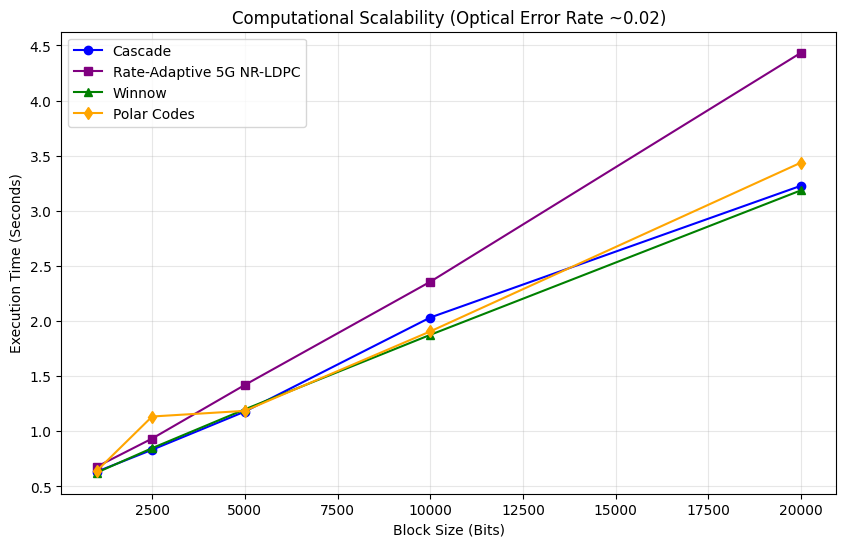

In [8]:
# --- Graph 4: Execution Time vs Block Size ---

plt.figure(figsize=(10, 6))

plt.plot(block_sizes, time_cascade, 'o-', color='blue', label='Cascade')
plt.plot(block_sizes, time_nr, 's-', color='purple', label='Rate-Adaptive 5G NR-LDPC')
plt.plot(block_sizes, time_winnow, '^-', color='green', label='Winnow')
plt.plot(block_sizes, time_polar, 'd-', color='orange', label='Polar Codes')

plt.xlabel('Block Size (Bits)')
plt.ylabel('Execution Time (Seconds)')
plt.title(f'Computational Scalability (Optical Error Rate ~{FIXED_ERR})')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

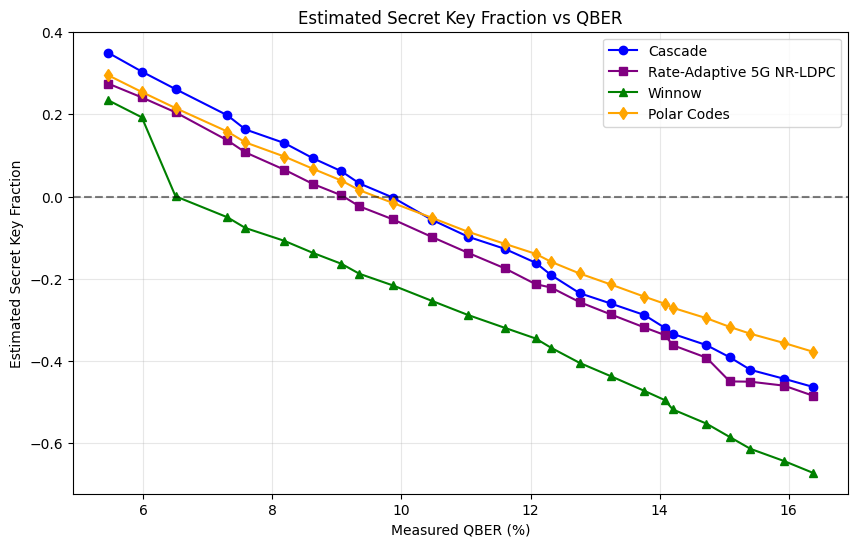

In [9]:
# --- Graph 5: Estimated Secret Key Fraction vs QBER ---

plt.figure(figsize=(10, 6))
for result, marker, color, label in (
    (results_cascade, "o-", "blue", "Cascade"),
    (results_nr, "s-", "purple", "Rate-Adaptive 5G NR-LDPC"),
    (results_winnow, "^-", "green", "Winnow"),
    (results_polar, "d-", "orange", "Polar Codes"),
):
    if result["qber"]:
        qber_values = np.asarray(result["qber"])
        efficiency = np.asarray(result["efficiency"])
        estimated = np.asarray([
            1 - (1 + f_ec) * binary_entropy(qber / 100)
            for f_ec, qber in zip(efficiency, qber_values)
        ])
        order = np.argsort(qber_values)
        plt.plot(qber_values[order], estimated[order], marker, color=color, label=label)

plt.xlabel("Measured QBER (%)")
plt.ylabel("Estimated Secret Key Fraction")
plt.title("Estimated Secret Key Fraction vs QBER")
plt.legend()
plt.grid(True, alpha=0.3)
plt.axhline(y=0, color="black", linestyle="--", alpha=0.5)
plt.show()

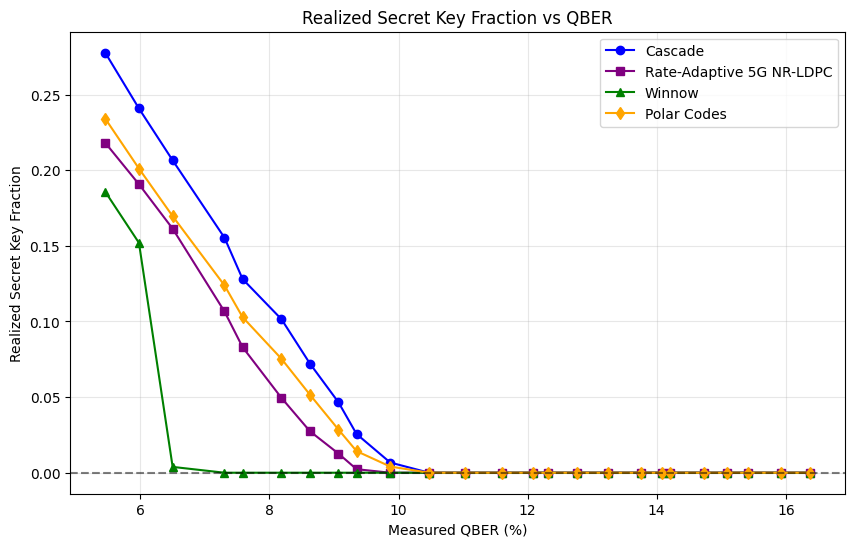

In [10]:
# --- Graph 6: Realized Secret Key Fraction vs QBER ---

plt.figure(figsize=(10, 6))
for result, marker, color, label in (
    (results_cascade, "o-", "blue", "Cascade"),
    (results_nr, "s-", "purple", "Rate-Adaptive 5G NR-LDPC"),
    (results_winnow, "^-", "green", "Winnow"),
    (results_polar, "d-", "orange", "Polar Codes"),
):
    if result["qber"]:
        qber_values = np.asarray(result["qber"])
        realized = np.asarray(result["skf"])
        order = np.argsort(qber_values)
        plt.plot(qber_values[order], realized[order], marker, color=color, label=label)

plt.xlabel("Measured QBER (%)")
plt.ylabel("Realized Secret Key Fraction")
plt.title("Realized Secret Key Fraction vs QBER")
plt.legend()
plt.grid(True, alpha=0.3)
plt.axhline(y=0, color="black", linestyle="--", alpha=0.5)
plt.show()